### Imports e Configuração de Paths

In [4]:
from __future__ import annotations

from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Localização robusta dos caminhos do projeto
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_CSV_PATH = PROJECT_ROOT / "data" / "raw" / "bbc-text.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "bbc_multinomial_pipeline.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print(f"Raiz do Projeto: {PROJECT_ROOT}")
print(f"Modelo a Testar: {MODEL_PATH} (Existe? {MODEL_PATH.exists()})")


Raiz do Projeto: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction
Modelo a Testar: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\models\bbc_multinomial_pipeline.joblib (Existe? True)


### Carregando Pipeline e Recuperando Dataset de Teste

In [5]:
# 1. Carrega o pipeline completo ajustado
pipeline = joblib.load(MODEL_PATH)

# 2. Carrega os dados brutos e refaz a separação com idêntica semente
df = pd.read_csv(RAW_CSV_PATH)
X = df["text"].astype(str)
y = df["category"].astype(str)

_, X_test, _, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Pipeline carregado com sucesso!")
print(f"Total de amostras no conjunto de teste: {len(X_test)} artigos")
print(f"Classes avaliadas: {list(pipeline.classes_)}")


Pipeline carregado com sucesso!
Total de amostras no conjunto de teste: 445 artigos
Classes avaliadas: [np.str_('business'), np.str_('entertainment'), np.str_('politics'), np.str_('sport'), np.str_('tech')]


### Execução da Inferência e Cálculo das Métricas Globais

In [6]:
# 1. Predição sobre os textos não vistos de teste
y_pred = pipeline.predict(X_test)

# 2. Cálculo dos indicadores globais
acuracia = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print("=" * 70)
print(" DESEMPENHO GLOBAL — MULTINOMIAL NAIVE BAYES")
print("=" * 70)
print(f"Acurácia Global          : {acuracia * 100:.2f}%")
print(f"F1-Score (Macro Average) : {f1_macro * 100:.2f}%")
print(f"F1-Score (Ponderado)     : {f1_weighted * 100:.2f}%")
print("=" * 70)


 DESEMPENHO GLOBAL — MULTINOMIAL NAIVE BAYES
Acurácia Global          : 98.43%
F1-Score (Macro Average) : 98.39%
F1-Score (Ponderado)     : 98.43%


### Relatório Detalhado por Classe e Persistência em `.txt`

In [7]:
labels = sorted(list(np.unique(y_test)))
report_dict = classification_report(y_test, y_pred, target_names=labels, output_dict=True)
report_str = classification_report(y_test, y_pred, target_names=labels, digits=4)

print(report_str)

# Persistência textual do relatório
report_file = REPORTS_DIR / "metricas_avaliacao.txt"
with open(report_file, "w", encoding="utf-8") as f:
    f.write("=" * 75 + "\n")
    f.write("RELATÓRIO DE AVALIAÇÃO DE DESEMPENHO — MULTINOMIAL NAIVE BAYES\n")
    f.write("Dataset: BBC News (445 amostras de teste)\n")
    f.write("=" * 75 + "\n\n")
    f.write(report_str + "\n")
    f.write("=" * 75 + "\n")

print(f"Relatório textual salvo em: {report_file}")


               precision    recall  f1-score   support

     business     0.9899    0.9608    0.9751       102
entertainment     0.9744    0.9870    0.9806        77
     politics     0.9651    0.9881    0.9765        84
        sport     1.0000    1.0000    1.0000       102
         tech     0.9875    0.9875    0.9875        80

     accuracy                         0.9843       445
    macro avg     0.9834    0.9847    0.9839       445
 weighted avg     0.9844    0.9843    0.9843       445

Relatório textual salvo em: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\metricas_avaliacao.txt


### Plotando a Matriz de Confusão com HeatMap

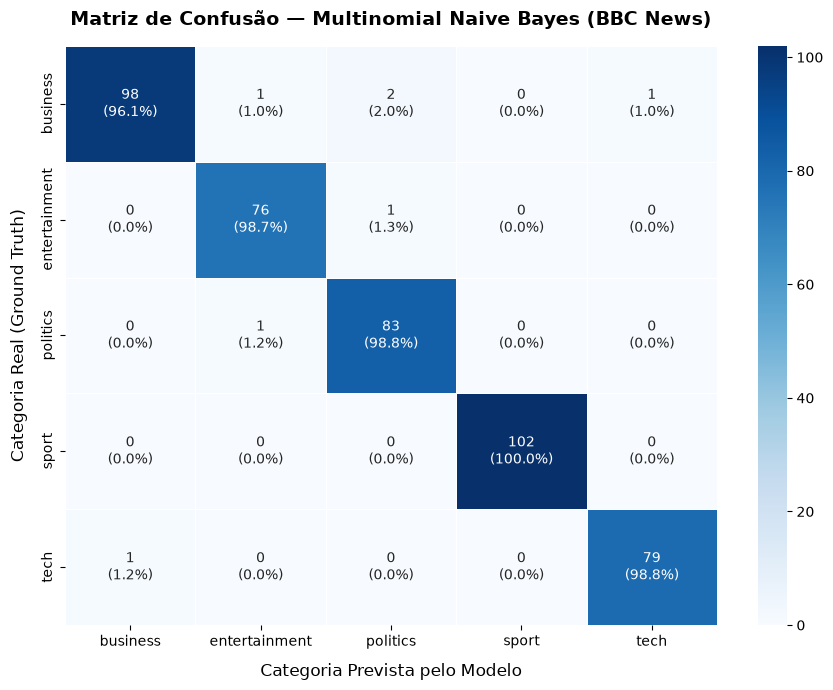

Matriz de confusão salva em: c:\Users\diego\Desktop\repositorios\bayes-bbc-prediction\reports\figures\matriz_confusao.png


In [8]:
cm = confusion_matrix(y_test, y_pred, labels=labels)
cm_percent = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100

# Montagem de anotações combinando contagem absoluta e porcentagem
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(len(labels)):
    for j in range(len(labels)):
        annot_matrix[i, j] = f"{cm[i, j]}\n({cm_percent[i, j]:.1f}%)"

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=annot_matrix,
    fmt="",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    linewidths=0.5,
)

plt.title("Matriz de Confusão — Multinomial Naive Bayes (BBC News)", fontsize=14, weight="bold", pad=15)
plt.xlabel("Categoria Prevista pelo Modelo", fontsize=12, labelpad=10)
plt.ylabel("Categoria Real (Ground Truth)", fontsize=12, labelpad=10)
plt.tight_layout()

cm_path = FIGURES_DIR / "matriz_confusao.png"
plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Matriz de confusão salva em: {cm_path}")


### Análise Crítica de Erro e Casos de Fronteira

In [9]:
erros_mask = (y_test != y_pred)
erros_df = pd.DataFrame({
    "Texto": X_test[erros_mask],
    "Real": y_test[erros_mask],
    "Previsto": y_pred[erros_mask],
})

print(f"Total de erros cometidos no teste: {len(erros_df)} de {len(y_test)} artigos ({len(erros_df)/len(y_test)*100:.2f}%)")
print("\nExemplos de Artigos Divergentes:")
display(erros_df.head(5))


Total de erros cometidos no teste: 7 de 445 artigos (1.57%)

Exemplos de Artigos Divergentes:


,Texto,Real,Previsto
1532,saudi ministry to employ women women will be e...,business,politics
230,tv show unites angolan families angolan famili...,entertainment,politics
1702,call to overhaul uk state pension the uk pensi...,business,politics
199,card fraudsters targeting web new safeguards...,business,tech
535,pc ownership to double by 2010 the number of...,tech,business
